## Sel 1: Setup

Impor library, set seed (`SEED = 42`), dan pilih `device` (CUDA, lalu MPS, lalu CPU).

In [1]:
import random
from dataclasses import dataclass

import matplotlib.pyplot as plt
import numpy as np
import torch
import torchvision
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

SEED = 44


def set_seed(seed):
    # Samakan seed di semua sumber acak supaya hasil bisa direproduksi
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def get_device():
    # Prioritas: CUDA (Windows/Colab) -> MPS (Mac Apple Silicon) -> CPU
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


set_seed(SEED)
device = get_device()

print(f"Device            : {device}")
print(f"torch version     : {torch.__version__}")
print(f"torchvision version: {torchvision.__version__}")

Device            : mps
torch version     : 2.11.0
torchvision version: 0.26.0


## Sel 2: Konfigurasi

Kumpulkan parameter dataset di objek `cfg` supaya tidak ada angka hardcode.

In [2]:
@dataclass
class Config:
    image_size: int = 28    # sisi gambar (persegi)
    channels: int = 1       # 1 = grayscale, 3 = RGB
    num_classes: int = 10   # jumlah kelas
    batch_size: int = 128
    num_workers: int = 0    # 0 = paling aman di Mac/Windows/notebook
    data_root: str = "./data"


cfg = Config()

## Sel 3: Transform, Dataset, DataLoader

Normalisasi gambar ke [-1, 1], muat Fashion-MNIST, dan bangun `train_loader`.

In [3]:
# Normalisasi per channel ke [-1, 1]: (x - 0.5) / 0.5
transform = transforms.Compose([
    transforms.Resize(cfg.image_size),   # no-op kalau sudah 28x28, berguna kalau ganti dataset
    transforms.ToTensor(),               # PIL -> tensor (C, H, W), nilai [0, 1]
    transforms.Normalize(
        mean=[0.5] * cfg.channels,
        std=[0.5] * cfg.channels,
    ),                                   # nilai jadi [-1, 1]
])

train_set = datasets.FashionMNIST(
    root=cfg.data_root,
    train=True,
    download=True,
    transform=transform,
)

# Generator khusus supaya urutan shuffle ikut reproducible
loader_gen = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    train_set,
    batch_size=cfg.batch_size,
    shuffle=True,
    num_workers=cfg.num_workers,
    pin_memory=(device.type == "cuda"),  # pin_memory hanya berguna untuk CUDA
    drop_last=True,                      # semua batch berukuran sama
    generator=loader_gen,
)

class_names = train_set.classes
print(f"Jumlah data   : {len(train_set)}")
print(f"Jumlah batch  : {len(train_loader)}")
print(f"Nama kelas    : {class_names}")

Jumlah data   : 60000
Jumlah batch  : 468
Nama kelas    : ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


## Sel 4: Cek Satu Batch

Pastikan shape, dtype, dan rentang nilai gambar serta label sesuai harapan.

In [4]:
images, labels = next(iter(train_loader))

print(f"images shape : {tuple(images.shape)}")  # (B, C, H, W) = (128, 1, 28, 28)
print(f"images dtype : {images.dtype}")         # float32
print(f"images min/max: {images.min().item():.3f} / {images.max().item():.3f}")  # harus dalam [-1, 1]
print(f"labels shape : {tuple(labels.shape)}")  # (B,) = (128,)
print(f"labels dtype : {labels.dtype}")         # int64
print(f"labels min/max: {labels.min().item()} / {labels.max().item()}")  # dalam [0, 9]

images shape : (128, 1, 28, 28)
images dtype : torch.float32
images min/max: -1.000 / 1.000
labels shape : (128,)
labels dtype : torch.int64
labels min/max: 0 / 9


## Sel 5: Grid Sampel per Kelas

Tampilkan sampel tiap kelas (satu baris per kelas) untuk cek visual dan kecocokan `class_names`.

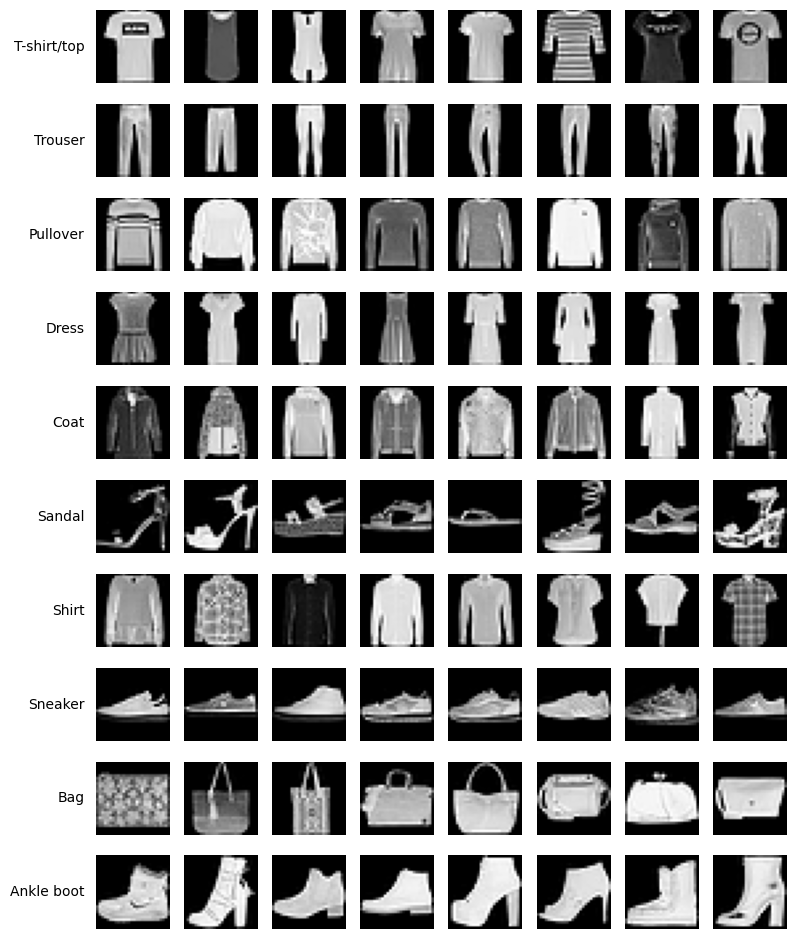

In [5]:
samples_per_class = 8

fig, axes = plt.subplots(
    cfg.num_classes, samples_per_class,
    figsize=(samples_per_class * 1.2, cfg.num_classes * 1.2),
)
fig.subplots_adjust(left=0.18)

targets = train_set.targets  # tensor (N,) berisi label seluruh data

for c in range(cfg.num_classes):
    idx = (targets == c).nonzero(as_tuple=True)[0][:samples_per_class]  # (samples_per_class,)
    batch = torch.stack([train_set[i][0] for i in idx])                 # (S, C, H, W)
    batch = (batch + 1) / 2                                             # balik ke [0, 1] untuk ditampilkan

    for j in range(samples_per_class):
        ax = axes[c, j]
        ax.imshow(batch[j, 0], cmap="gray", vmin=0, vmax=1)             # (H, W)
        ax.axis("off")
        if j == 0:
            ax.text(-0.15, 0.5, class_names[c], transform=ax.transAxes,
                    ha="right", va="center", fontsize=10)

plt.show()

## Sel 6: Verifikasi Visual

Tampilkan 32 gambar pertama dari satu batch dengan nama kelasnya, lalu 16 sampel acak kelas "Shirt" (ganti `SAMPLE_SEED` untuk sampel lain).

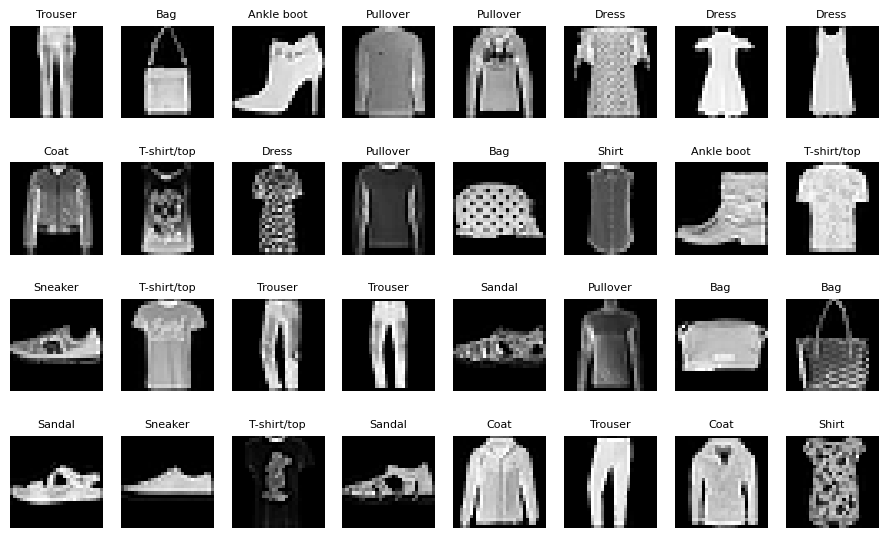

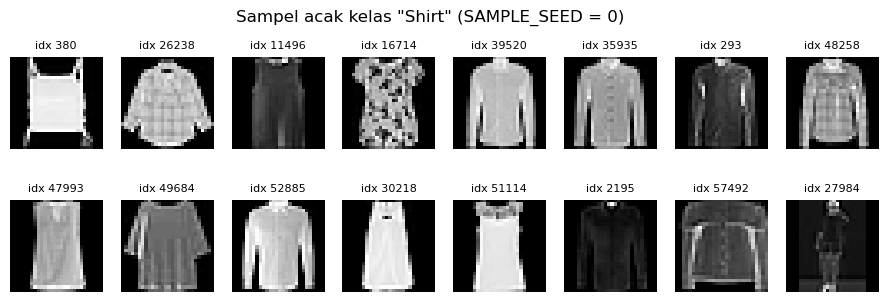

In [6]:
SAMPLE_SEED = 0          # ganti angka ini untuk melihat sampel "Shirt" yang lain
SHIRT_SAMPLES = 16       # jumlah sampel acak dari kelas "Shirt"

# --- Bagian 1: 32 gambar pertama dari satu batch, grid 4 x 8 ---
grid_rows, grid_cols = 4, 8
num_show = grid_rows * grid_cols                          # 32

batch_images, batch_labels = next(iter(train_loader))     # (B, C, H, W), (B,)
shown = (batch_images[:num_show] + 1) / 2                 # (32, C, H, W), balik ke [0, 1]

fig, axes = plt.subplots(grid_rows, grid_cols, figsize=(grid_cols * 1.4, grid_rows * 1.7))
for k, ax in enumerate(axes.flat):
    ax.imshow(shown[k, 0], cmap="gray", vmin=0, vmax=1)  # (H, W)
    ax.set_title(class_names[batch_labels[k].item()], fontsize=8)
    ax.axis("off")
plt.show()

# --- Bagian 2: sampel acak dari seluruh data kelas "Shirt" ---
shirt_label = class_names.index("Shirt")
shirt_idx = (train_set.targets == shirt_label).nonzero(as_tuple=True)[0]  # (N_shirt,)

sample_gen = torch.Generator().manual_seed(SAMPLE_SEED)
perm = torch.randperm(len(shirt_idx), generator=sample_gen)[:SHIRT_SAMPLES]  # (SHIRT_SAMPLES,)
chosen = shirt_idx[perm]                                                     # (SHIRT_SAMPLES,)

shirts = torch.stack([train_set[i][0] for i in chosen.tolist()])  # (SHIRT_SAMPLES, C, H, W)
shirts = (shirts + 1) / 2                                         # balik ke [0, 1]

shirt_cols = 8
shirt_rows = SHIRT_SAMPLES // shirt_cols
fig, axes = plt.subplots(shirt_rows, shirt_cols, figsize=(shirt_cols * 1.4, shirt_rows * 1.7))
for k, ax in enumerate(axes.flat):
    ax.imshow(shirts[k, 0], cmap="gray", vmin=0, vmax=1)  # (H, W)
    ax.set_title(f"idx {chosen[k].item()}", fontsize=8)
    ax.axis("off")
fig.suptitle(f'Sampel acak kelas "Shirt" (SAMPLE_SEED = {SAMPLE_SEED})')
plt.show()

## Sel 7: Konfigurasi Generator

Tambahkan `latent_dim` (ukuran noise `z`) dan `embed_dim` (ukuran embedding label) ke `Config` lewat subclass, tanpa mengubah Sel 2.

In [7]:
@dataclass
class GanConfig(Config):
    latent_dim: int = 100   # ukuran noise z
    embed_dim: int = 32     # ukuran embedding label


# Pertahankan nilai Config lama, lalu tambahkan field baru
cfg = GanConfig(**vars(cfg))
print(cfg)

GanConfig(image_size=28, channels=1, num_classes=10, batch_size=128, num_workers=0, data_root='./data', latent_dim=100, embed_dim=32)


## Sel 8: Class Generator

Embedding label digabung (concat) dengan `z`, diproyeksikan ke peta fitur kecil, lalu di-upsample dengan `ConvTranspose2d` sampai ukuran gambar. Output `tanh` di [-1, 1]. Dengan `refine=True`, tahap upsample terakhir diikuti dua `Conv2d` 3x3 di resolusi gambar untuk merapikan detail (bawaan: `False`, arsitektur awal).

In [8]:
import torch.nn as nn


class Generator(nn.Module):
    def __init__(self, cfg, base_channels=128, refine=False):
        super().__init__()
        # Dua tahap upsample x2, jadi sisi gambar harus habis dibagi 4
        assert cfg.image_size % 4 == 0, "cfg.image_size harus habis dibagi 4"
        self.base_channels = base_channels
        self.refine = refine  # True: tambah dua Conv2d 3x3 di resolusi gambar
        self.init_size = cfg.image_size // 4  # 28 -> 7

        # Label (B,) int64 -> vektor (B, embed_dim)
        self.label_embed = nn.Embedding(cfg.num_classes, cfg.embed_dim)

        # (B, latent_dim + embed_dim) -> (B, base_channels * init_size * init_size)
        self.project = nn.Linear(
            cfg.latent_dim + cfg.embed_dim,
            base_channels * self.init_size ** 2,
        )

        layers = [
            nn.BatchNorm2d(base_channels),
            nn.ReLU(inplace=True),
            # (B, base, s, s) -> (B, base // 2, 2s, 2s)
            nn.ConvTranspose2d(base_channels, base_channels // 2, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(base_channels // 2),
            nn.ReLU(inplace=True),
        ]
        if refine:
            mid = base_channels // 4
            layers += [
                # (B, base // 2, 2s, 2s) -> (B, mid, 4s, 4s)
                nn.ConvTranspose2d(base_channels // 2, mid, kernel_size=4, stride=2, padding=1),
                nn.BatchNorm2d(mid),
                nn.ReLU(inplace=True),
                # Dua Conv2d 3x3 di resolusi gambar: (B, mid, H, W) -> (B, mid, H, W) -> (B, C, H, W)
                nn.Conv2d(mid, mid, kernel_size=3, padding=1),
                nn.BatchNorm2d(mid),
                nn.ReLU(inplace=True),
                nn.Conv2d(mid, cfg.channels, kernel_size=3, padding=1),
            ]
        else:
            # (B, base // 2, 2s, 2s) -> (B, C, 4s, 4s) = (B, C, H, W)
            layers.append(nn.ConvTranspose2d(base_channels // 2, cfg.channels, kernel_size=4, stride=2, padding=1))
        layers.append(nn.Tanh())  # output di [-1, 1], sama dengan normalisasi data
        self.net = nn.Sequential(*layers)

    def forward(self, z, labels):
        # z: (B, latent_dim), labels: (B,) int64
        emb = self.label_embed(labels)                 # (B, embed_dim)
        x = torch.cat([z, emb], dim=1)                 # (B, latent_dim + embed_dim)
        x = self.project(x)                            # (B, base * s * s)
        x = x.view(x.size(0), self.base_channels, self.init_size, self.init_size)  # (B, base, s, s)
        return self.net(x)                             # (B, C, H, W)

## Sel 9: Uji Generator

Buat Generator, pindahkan ke `device`, beri `z` dan label acak, lalu cek shape output, rentang nilai, dan jumlah parameter.

In [9]:
generator = Generator(cfg, base_channels=256, refine=True).to(device)

z = torch.randn(cfg.batch_size, cfg.latent_dim, device=device)                  # (B, latent_dim)
labels = torch.randint(0, cfg.num_classes, (cfg.batch_size,), device=device)    # (B,) int64

with torch.no_grad():
    fake = generator(z, labels)                                                 # (B, C, H, W)

print(f"output shape   : {tuple(fake.shape)}")  # harapan: (128, 1, 28, 28)
print(f"output min/max : {fake.min().item():.3f} / {fake.max().item():.3f}")  # harus dalam [-1, 1]
print(f"jumlah parameter: {sum(p.numel() for p in generator.parameters()):,}")

output shape   : (128, 1, 28, 28)
output min/max : -0.885 / 0.954
jumlah parameter: 2,362,753


## Sel 10: Class Discriminator

Label di-embed jadi peta `(B, 1, H, W)`, ditumpuk ke gambar sebagai channel tambahan (concat), lalu dua konvolusi stride 2 dan satu Linear menghasilkan logit asli/palsu per gambar.

In [10]:
class Discriminator(nn.Module):
    def __init__(self, cfg, base_channels=64):
        super().__init__()
        # Dua tahap downsample /2, jadi sisi gambar harus habis dibagi 4
        assert cfg.image_size % 4 == 0, "cfg.image_size harus habis dibagi 4"
        self.image_size = cfg.image_size
        final_size = cfg.image_size // 4  # 28 -> 7

        # Label (B,) int64 -> satu nilai per piksel (B, H*W), nanti di-reshape jadi 1 channel
        self.label_embed = nn.Embedding(cfg.num_classes, cfg.image_size ** 2)

        self.net = nn.Sequential(
            # (B, C+1, H, W) -> (B, base, H/2, W/2)
            nn.Conv2d(cfg.channels + 1, base_channels, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2, inplace=True),
            # (B, base, H/2, W/2) -> (B, 2*base, H/4, W/4)
            nn.Conv2d(base_channels, base_channels * 2, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(base_channels * 2),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Flatten(),  # (B, 2*base*final_size*final_size)
            nn.Linear(base_channels * 2 * final_size ** 2, 1),  # logit mentah, tanpa sigmoid
        )

    def forward(self, images, labels):
        # images: (B, C, H, W), labels: (B,) int64
        label_map = self.label_embed(labels)                                  # (B, H*W)
        label_map = label_map.view(-1, 1, self.image_size, self.image_size)   # (B, 1, H, W)
        x = torch.cat([images, label_map], dim=1)                             # (B, C+1, H, W)
        return self.net(x).squeeze(1)                                         # (B,)

## Sel 11: Uji Discriminator

Beri satu batch gambar asli dan satu batch gambar buatan Generator ke Discriminator, lalu cek shape logit, rentang nilainya, dan jumlah parameter.

In [11]:
discriminator = Discriminator(cfg, base_channels=128).to(device)

real_images, real_labels = next(iter(train_loader))  # (B, C, H, W), (B,)
real_images, real_labels = real_images.to(device), real_labels.to(device)

z = torch.randn(cfg.batch_size, cfg.latent_dim, device=device)  # (B, latent_dim)

with torch.no_grad():
    fake_images = generator(z, real_labels)               # (B, C, H, W)
    real_logits = discriminator(real_images, real_labels) # (B,)
    fake_logits = discriminator(fake_images, real_labels) # (B,)

print(f"real logits shape : {tuple(real_logits.shape)}")  # harapan: (128,)
print(f"fake logits shape : {tuple(fake_logits.shape)}")  # harapan: (128,)
print(f"real logits min/max: {real_logits.min().item():.3f} / {real_logits.max().item():.3f}")
print(f"fake logits min/max: {fake_logits.min().item():.3f} / {fake_logits.max().item():.3f}")
print(f"jumlah parameter  : {sum(p.numel() for p in discriminator.parameters()):,}")

real logits shape : (128,)
fake logits shape : (128,)
real logits min/max: -0.236 / 1.196
fake logits min/max: -0.531 / 0.593
jumlah parameter  : 549,665


## Sel 12: Konfigurasi Training

Tambahkan `lr_g`, `lr_d`, dan `beta1` ke config lewat subclass, tanpa mengubah sel sebelumnya.

In [12]:
@dataclass
class TrainConfig(GanConfig):
    lr_g: float = 2e-4    # learning rate Generator
    lr_d: float = 4e-4    # learning rate Discriminator
    beta1: float = 0.5    # beta1 Adam (beta2 dibiarkan default 0.999)


# Pertahankan nilai config lama, lalu tambahkan field baru
cfg = TrainConfig(**vars(cfg))
print(cfg)

TrainConfig(image_size=28, channels=1, num_classes=10, batch_size=128, num_workers=0, data_root='./data', latent_dim=100, embed_dim=32, lr_g=0.0002, lr_d=0.0004, beta1=0.5)


## Sel 13: Fungsi Loss

`BCEWithLogitsLoss` dipakai untuk loss Discriminator (asli = 1, palsu = 0) dan loss Generator versi non-saturating (gambar palsu diberi target 1).

In [13]:
criterion = nn.BCEWithLogitsLoss()  # sigmoid + BCE dalam satu operasi, stabil secara numerik


def d_loss_fn(real_logits, fake_logits):
    # real_logits, fake_logits: (B,) logit mentah dari Discriminator
    real_loss = criterion(real_logits, torch.ones_like(real_logits))   # target asli = 1, hasil skalar
    fake_loss = criterion(fake_logits, torch.zeros_like(fake_logits))  # target palsu = 0, hasil skalar
    return real_loss + fake_loss


def g_loss_fn(fake_logits):
    # fake_logits: (B,); non-saturating: Generator ingin gambar palsunya dianggap asli (target 1)
    return criterion(fake_logits, torch.ones_like(fake_logits))

## Sel 14: Optimizer

Dua optimizer Adam terpisah untuk Generator dan Discriminator, dengan learning rate dan `beta1` dari `cfg`.

In [14]:
# Dua optimizer terpisah: satu untuk parameter Generator, satu untuk Discriminator
opt_g = torch.optim.Adam(generator.parameters(), lr=cfg.lr_g, betas=(cfg.beta1, 0.999))
opt_d = torch.optim.Adam(discriminator.parameters(), lr=cfg.lr_d, betas=(cfg.beta1, 0.999))

## Sel 15: Uji Loss dan Optimizer

Cek loss pada logit nol (nilainya bisa dihitung manual), loss pada logit dari Sel 11, dan kesesuaian optimizer dengan `cfg`.

In [15]:
# Logit nol berarti sigmoid = 0.5, jadi nilai loss bisa dihitung analitik
zero_logits = torch.zeros(cfg.batch_size, device=device)  # (B,)

print(f"d_loss (logit nol)    : {d_loss_fn(zero_logits, zero_logits).item():.4f}")  # harapan: 1.3863 (2 * ln 2)
print(f"g_loss (logit nol)    : {g_loss_fn(zero_logits).item():.4f}")               # harapan: 0.6931 (ln 2)

# Logit dari Sel 11 (model belum dilatih)
print(f"d_loss (logit Sel 11) : {d_loss_fn(real_logits, fake_logits).item():.4f}")
print(f"g_loss (logit Sel 11) : {g_loss_fn(fake_logits).item():.4f}")

for name, opt, lr in [("opt_g", opt_g, cfg.lr_g), ("opt_d", opt_d, cfg.lr_d)]:
    group = opt.param_groups[0]
    sesuai = group["lr"] == lr and group["betas"][0] == cfg.beta1
    print(f"{name}: lr={group['lr']}, betas={group['betas']}, sesuai cfg: {sesuai}")

d_loss (logit nol)    : 1.3863
g_loss (logit nol)    : 0.6931
d_loss (logit Sel 11) : 1.2808
g_loss (logit Sel 11) : 0.6811
opt_g: lr=0.0002, betas=(0.5, 0.999), sesuai cfg: True
opt_d: lr=0.0004, betas=(0.5, 0.999), sesuai cfg: True


## Sel 15b: Inisialisasi Bobot dan Nama Run

Pengaturan per run: `USE_DCGAN_INIT`, `EPOCHS`, dan nama folder otomatis `RUN_NAME` (dari ukuran G dan D, jenis inisialisasi, `SEED`, dan `EPOCHS`). Inisialisasi DCGAN: bobot Conv, ConvTranspose, dan Linear ~ N(0, 0.02), BatchNorm ~ N(1, 0.02), bias 0, dan `nn.Embedding` dibiarkan bawaan. Dipasang setelah optimizer dibuat (Sel 14), aman karena isi bobot diubah di tempat. Untuk run dengan seed lain, ubah `SEED` di Sel 1. `ema_generator` adalah salinan Generator yang bobotnya dirata-ratakan (EMA, peluruhan `EMA_DECAY`) selama training, dan nama run mendapat akhiran `_ema`.

In [16]:
import copy

USE_DCGAN_INIT = False  # False = inisialisasi bawaan PyTorch
INIT_STD = 0.02         # simpangan baku bobot (DCGAN)
EPOCHS = 100            # jumlah epoch training, dipakai di Sel 16
EMA_DECAY = 0.999       # faktor peluruhan rata-rata bergerak bobot Generator (EMA)

# Nama run (folder checkpoint dan gambar) dibentuk otomatis dari pengaturan run ini
init_tag = "dcgan" if USE_DCGAN_INIT else "noinit"
lr_tag = "" if cfg.lr_d == cfg.lr_g else f"_lrd{cfg.lr_d:g}"  # penanda jika learning rate D berbeda dari G
conv_tag = "_conv" if generator.refine else ""
RUN_NAME = f"run_g{generator.base_channels}{conv_tag}_d{discriminator.net[0].out_channels}_{init_tag}{lr_tag}_s{SEED}_e{EPOCHS}_ema"


def dcgan_init(module):
    # Bobot Conv, ConvTranspose, dan Linear ~ N(0, INIT_STD), bias 0.
    # BatchNorm: bobot ~ N(1, INIT_STD), bias 0.
    # nn.Embedding dibiarkan bawaan: label embedding tidak ada di DCGAN asli.
    if isinstance(module, (nn.Conv2d, nn.ConvTranspose2d, nn.Linear)):
        nn.init.normal_(module.weight, mean=0.0, std=INIT_STD)
        nn.init.zeros_(module.bias)
    elif isinstance(module, nn.BatchNorm2d):
        nn.init.normal_(module.weight, mean=1.0, std=INIT_STD)
        nn.init.zeros_(module.bias)


if USE_DCGAN_INIT:
    generator.apply(dcgan_init)
    discriminator.apply(dcgan_init)

# Salinan Generator yang bobotnya dirata-ratakan sepanjang training (diperbarui di Sel 18)
ema_generator = copy.deepcopy(generator).eval()

# Aliran angka acak untuk training dibuat sama, dengan atau tanpa inisialisasi di atas
set_seed(SEED)

print(f"Run: {RUN_NAME} | init DCGAN: {USE_DCGAN_INIT}")
layers = [
    ("G proyeksi (Linear)", generator.project),
    ("G BatchNorm 1", generator.net[0]),
    ("G ConvTranspose 1", generator.net[2]),
    ("G embedding", generator.label_embed),
    ("D Conv 1", discriminator.net[0]),
    ("D Linear akhir", discriminator.net[-1]),
    ("D embedding", discriminator.label_embed),
]
for name, layer in layers:
    w = layer.weight
    print(f"{name:<22} mean {w.mean().item():7.3f} | std {w.std().item():7.4f}")

# Logit awal D pada batch asli dari Sel 11 (bandingkan dengan keluaran Sel 11)
with torch.no_grad():
    init_logits = discriminator(real_images, real_labels)  # (B,)
print(f"Logit awal D: min/max {init_logits.min().item():.3f} / {init_logits.max().item():.3f}")

Run: run_g256_conv_d128_noinit_lrd0.0004_s44_e100_ema | init DCGAN: False
G proyeksi (Linear)    mean  -0.000 | std  0.0502
G BatchNorm 1          mean   1.000 | std  0.0000
G ConvTranspose 1      mean  -0.000 | std  0.0128
G embedding            mean  -0.065 | std  1.0157
D Conv 1               mean  -0.003 | std  0.1032
D Linear akhir         mean  -0.000 | std  0.0052
D embedding            mean  -0.017 | std  0.9955
Logit awal D: min/max -0.236 / 1.196


## Sel 16: Konfigurasi Loop Training

Tambahkan `epochs`, `snap_per_class`, `ckpt_dir` (folder penyimpanan bobot), dan `ckpt_every` (simpan checkpoint tiap berapa epoch) ke config lewat subclass. `epochs` dan folder `ckpt_dir` diambil dari `EPOCHS` dan `RUN_NAME` di Sel 15b.

In [17]:
@dataclass
class LoopConfig(TrainConfig):
    epochs: int = EPOCHS                    # jumlah epoch training
    snap_per_class: int = 8             # gambar per kelas pada snapshot Generator
    ckpt_dir: str = f"./checkpoints/{RUN_NAME}"   # folder penyimpanan bobot
    ckpt_every: int = 10                # simpan checkpoint tiap berapa epoch


# Pertahankan nilai config lama, lalu tambahkan field baru
cfg = LoopConfig(**vars(cfg))
print(cfg)

LoopConfig(image_size=28, channels=1, num_classes=10, batch_size=128, num_workers=0, data_root='./data', latent_dim=100, embed_dim=32, lr_g=0.0002, lr_d=0.0004, beta1=0.5, epochs=100, snap_per_class=8, ckpt_dir='./checkpoints/run_g256_conv_d128_noinit_lrd0.0004_s44_e100_ema', ckpt_every=10)


## Sel 17: Noise dan Label Tetap

Buat `fixed_z` dan `fixed_labels` (tiap kelas `snap_per_class` gambar) untuk snapshot Generator tiap epoch.

In [18]:
# Noise dan label tetap supaya snapshot antar epoch bisa dibandingkan
snap_gen = torch.Generator().manual_seed(SEED)
fixed_z = torch.randn(
    cfg.num_classes * cfg.snap_per_class, cfg.latent_dim, generator=snap_gen
).to(device)                                                                       # (N, latent_dim)
fixed_labels = torch.arange(cfg.num_classes).repeat_interleave(cfg.snap_per_class).to(device)  # (N,)

print(f"fixed_z shape      : {tuple(fixed_z.shape)}")
print(f"fixed_labels shape : {tuple(fixed_labels.shape)}")

fixed_z shape      : (80, 100)
fixed_labels shape : (80,)


## Sel 18: Fungsi `train_one_epoch`

Satu epoch penuh: update Discriminator lalu Generator di tiap batch. Mengembalikan rata-rata `loss_d`, `loss_g`, `D(real)`, dan `D(fake)`. Setelah tiap update Generator, `ema_update()` memperbarui salinan EMA.

In [19]:
# Tensor float (bobot dan statistik BatchNorm) milik G dan salinan EMA; state_dict() berbagi memori dengan modelnya
ema_tensors = [v for v in ema_generator.state_dict().values() if v.dtype.is_floating_point]
live_tensors = [v for v in generator.state_dict().values() if v.dtype.is_floating_point]


def ema_update():
    # ema = EMA_DECAY * ema + (1 - EMA_DECAY) * bobot G saat ini
    with torch.no_grad():
        for ema_t, live_t in zip(ema_tensors, live_tensors):
            ema_t.lerp_(live_t, 1 - EMA_DECAY)


def train_one_epoch():
    # Jumlahkan sebagai tensor di device; .item() hanya dipanggil sekali di akhir epoch
    sums = torch.zeros(4, device=device)  # [loss_d, loss_g, D(real), D(fake)]

    for real_images, real_labels in train_loader:
        real_images = real_images.to(device)  # (B, C, H, W)
        real_labels = real_labels.to(device)  # (B,)
        batch_size = real_images.size(0)      # B, selalu sama karena drop_last=True

        z = torch.randn(batch_size, cfg.latent_dim, device=device)                     # (B, latent_dim)
        fake_labels = torch.randint(0, cfg.num_classes, (batch_size,), device=device)  # (B,)
        fake_images = generator(z, fake_labels)                                        # (B, C, H, W)

        # --- Update Discriminator ---
        real_logits = discriminator(real_images, real_labels)           # (B,)
        fake_logits = discriminator(fake_images.detach(), fake_labels)  # (B,), detach: gradien tidak masuk ke G
        loss_d = d_loss_fn(real_logits, fake_logits)
        opt_d.zero_grad()
        loss_d.backward()
        opt_d.step()

        # --- Update Generator (D sudah diperbarui, gambar palsu tidak di-detach) ---
        loss_g = g_loss_fn(discriminator(fake_images, fake_labels))
        opt_g.zero_grad()
        loss_g.backward()
        opt_g.step()
        ema_update()

        sums += torch.stack([
            loss_d.detach(),
            loss_g.detach(),
            torch.sigmoid(real_logits.detach()).mean(),
            torch.sigmoid(fake_logits.detach()).mean(),
        ])

    loss_d_avg, loss_g_avg, d_real_avg, d_fake_avg = (sums / len(train_loader)).tolist()
    return {"loss_d": loss_d_avg, "loss_g": loss_g_avg, "d_real": d_real_avg, "d_fake": d_fake_avg}

## Sel 19: Loop Training

Jalankan `cfg.epochs` epoch, catat `history`, simpan snapshot Generator, dan simpan checkpoint bobot bernomor epoch (`cgan_epoch_XXX.pt`) tiap `cfg.ckpt_every` epoch dan di epoch terakhir, tanpa saling menimpa. Checkpoint juga berisi bobot `ema_generator`.

In [20]:
import time
from pathlib import Path

ckpt_dir = Path(cfg.ckpt_dir)
ckpt_dir.mkdir(parents=True, exist_ok=True)

history = {"loss_d": [], "loss_g": [], "d_real": [], "d_fake": []}
snapshots = []  # satu elemen per epoch: (N, C, H, W) di CPU, rentang [-1, 1]

generator.train()
discriminator.train()
print(f"Checkpoint disimpan di: {ckpt_dir.resolve()}")

for epoch in range(1, cfg.epochs + 1):
    start = time.time()
    stats = train_one_epoch()
    for key, value in stats.items():
        history[key].append(value)

    # Snapshot dari noise tetap; eval() supaya BatchNorm tidak memakai statistik batch snapshot
    generator.eval()
    with torch.no_grad():
        snapshots.append(generator(fixed_z, fixed_labels).cpu())  # (N, C, H, W)
    generator.train()

    # Simpan tiap cfg.ckpt_every epoch dan di epoch terakhir; nama berisi nomor epoch, jadi tidak menimpa
    if epoch % cfg.ckpt_every == 0 or epoch == cfg.epochs:
        torch.save({
            "epoch": epoch,
            "generator": generator.state_dict(),
            "ema_generator": ema_generator.state_dict(),
            "discriminator": discriminator.state_dict(),
        }, ckpt_dir / f"cgan_epoch_{epoch:03d}.pt")

    print(
        f"Epoch {epoch:>3}/{cfg.epochs} | loss_d {stats['loss_d']:.4f} | loss_g {stats['loss_g']:.4f} | "
        f"D(real) {stats['d_real']:.3f} | D(fake) {stats['d_fake']:.3f} | {time.time() - start:.1f}s"
    )

Checkpoint disimpan di: /Users/maulidahelyati/Library/CloudStorage/GoogleDrive-maulida.helya@gmail.com/My Drive/Tugas Gen AI/Tugas_Vibe_Coding/notebooks/checkpoints/run_g256_conv_d128_noinit_lrd0.0004_s44_e100_ema
Epoch   1/100 | loss_d 1.1790 | loss_g 1.4776 | D(real) 0.597 | D(fake) 0.400 | 30.9s
Epoch   2/100 | loss_d 1.1466 | loss_g 1.3698 | D(real) 0.605 | D(fake) 0.393 | 30.5s
Epoch   3/100 | loss_d 1.2284 | loss_g 1.1860 | D(real) 0.578 | D(fake) 0.421 | 32.8s
Epoch   4/100 | loss_d 1.2629 | loss_g 1.0977 | D(real) 0.565 | D(fake) 0.435 | 42.3s
Epoch   5/100 | loss_d 1.2779 | loss_g 1.0802 | D(real) 0.559 | D(fake) 0.441 | 56.6s
Epoch   6/100 | loss_d 1.2942 | loss_g 1.0625 | D(real) 0.554 | D(fake) 0.446 | 51.8s
Epoch   7/100 | loss_d 1.3045 | loss_g 1.0431 | D(real) 0.551 | D(fake) 0.449 | 44.8s
Epoch   8/100 | loss_d 1.3166 | loss_g 1.0280 | D(real) 0.546 | D(fake) 0.454 | 41.3s
Epoch   9/100 | loss_d 1.3228 | loss_g 1.0113 | D(real) 0.544 | D(fake) 0.456 | 37.2s
Epoch  10/10

## Sel 20: Konfigurasi Gambar

Tambahkan `fig_dir` (folder penyimpanan PNG) ke config lewat subclass.

In [21]:
@dataclass
class EvalConfig(LoopConfig):
    fig_dir: str = f"./figures/{RUN_NAME}"    # folder penyimpanan gambar (PNG)


# Pertahankan nilai config lama, lalu tambahkan field baru
cfg = EvalConfig(**vars(cfg))
print(cfg)

EvalConfig(image_size=28, channels=1, num_classes=10, batch_size=128, num_workers=0, data_root='./data', latent_dim=100, embed_dim=32, lr_g=0.0002, lr_d=0.0004, beta1=0.5, epochs=100, snap_per_class=8, ckpt_dir='./checkpoints/run_g256_conv_d128_noinit_lrd0.0004_s44_e100_ema', ckpt_every=10, fig_dir='./figures/run_g256_conv_d128_noinit_lrd0.0004_s44_e100_ema')


## Sel 21: Kurva Training

Plot `loss_d` dan `loss_g`, serta `D(real)` dan `D(fake)` per epoch. Garis putus-putus di 0.5 menandai titik seimbang. Gambar disimpan ke `fig_dir`.

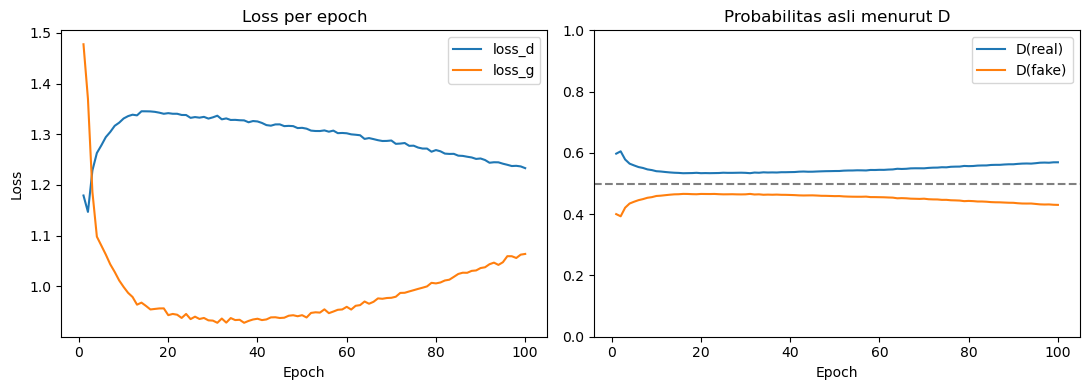

In [22]:
from pathlib import Path

fig_dir = Path(cfg.fig_dir)
fig_dir.mkdir(parents=True, exist_ok=True)

epoch_axis = range(1, len(history["loss_d"]) + 1)

fig, (ax_loss, ax_prob) = plt.subplots(1, 2, figsize=(11, 4))

ax_loss.plot(epoch_axis, history["loss_d"], label="loss_d")
ax_loss.plot(epoch_axis, history["loss_g"], label="loss_g")
ax_loss.set_title("Loss per epoch")
ax_loss.set_xlabel("Epoch")
ax_loss.set_ylabel("Loss")
ax_loss.legend()

ax_prob.plot(epoch_axis, history["d_real"], label="D(real)")
ax_prob.plot(epoch_axis, history["d_fake"], label="D(fake)")
ax_prob.axhline(0.5, linestyle="--", color="gray")  # titik seimbang: D tidak bisa membedakan
ax_prob.set_ylim(0, 1)
ax_prob.set_title("Probabilitas asli menurut D")
ax_prob.set_xlabel("Epoch")
ax_prob.legend()

fig.tight_layout()
fig.savefig(fig_dir / "01_kurva_training.png", dpi=150)
plt.show()

## Sel 22: Snapshot Generator per Epoch

Tampilkan snapshot dari `fixed_z` pada beberapa epoch terpilih, satu baris per kelas, untuk melihat perkembangan gambar. Gambar disimpan ke `fig_dir`.

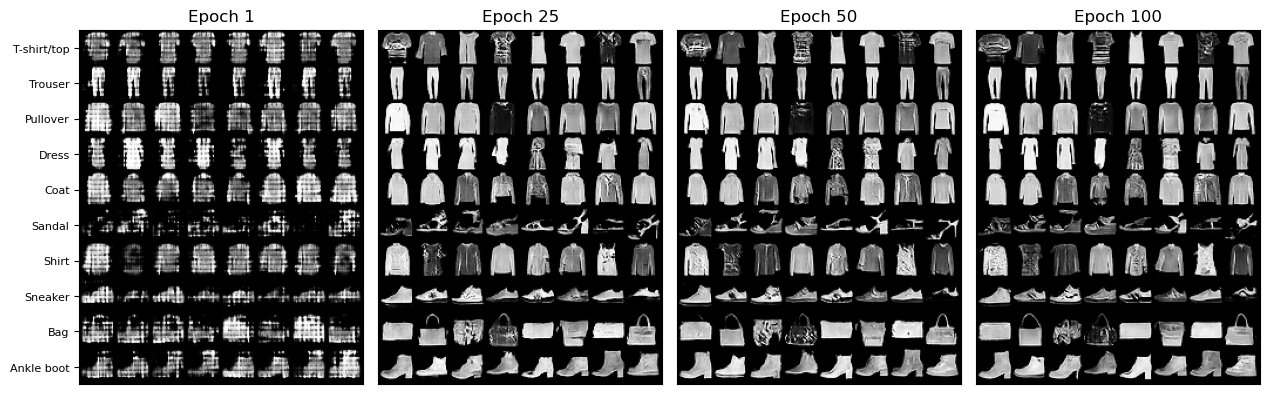

In [23]:
from torchvision.utils import make_grid

# Epoch terpilih (1-based): awal, seperempat, setengah, dan akhir
last_epoch = len(snapshots)
snap_epochs = sorted({1, max(1, last_epoch // 4), max(1, last_epoch // 2), last_epoch})

fig, axes = plt.subplots(1, len(snap_epochs), figsize=(len(snap_epochs) * 3.2, 6.5))
for k, (ax, ep) in enumerate(zip(np.atleast_1d(axes), snap_epochs)):
    imgs = (snapshots[ep - 1] + 1) / 2                           # (N, C, H, W), balik ke [0, 1]
    grid = make_grid(imgs, nrow=cfg.snap_per_class, padding=2)   # (3, H', W'), satu baris per kelas
    ax.imshow(grid.permute(1, 2, 0))                             # (H', W', 3)
    ax.set_title(f"Epoch {ep}")
    ax.set_xticks([])
    if k == 0:
        row_h = grid.shape[1] / cfg.num_classes
        ax.set_yticks([(r + 0.5) * row_h for r in range(cfg.num_classes)])
        ax.set_yticklabels(class_names, fontsize=8)
    else:
        ax.set_yticks([])

fig.tight_layout()
fig.savefig(fig_dir / "02_snapshot_per_epoch.png", dpi=150)
plt.show()

## Sel 23: Hasil Akhir per Kelas

Buat gambar dengan `z` baru (ganti `EVAL_SEED` untuk sampel lain), satu baris per kelas. Baris yang isinya mirip semua menandakan kemungkinan mode collapse. Gambar disimpan ke `fig_dir`.

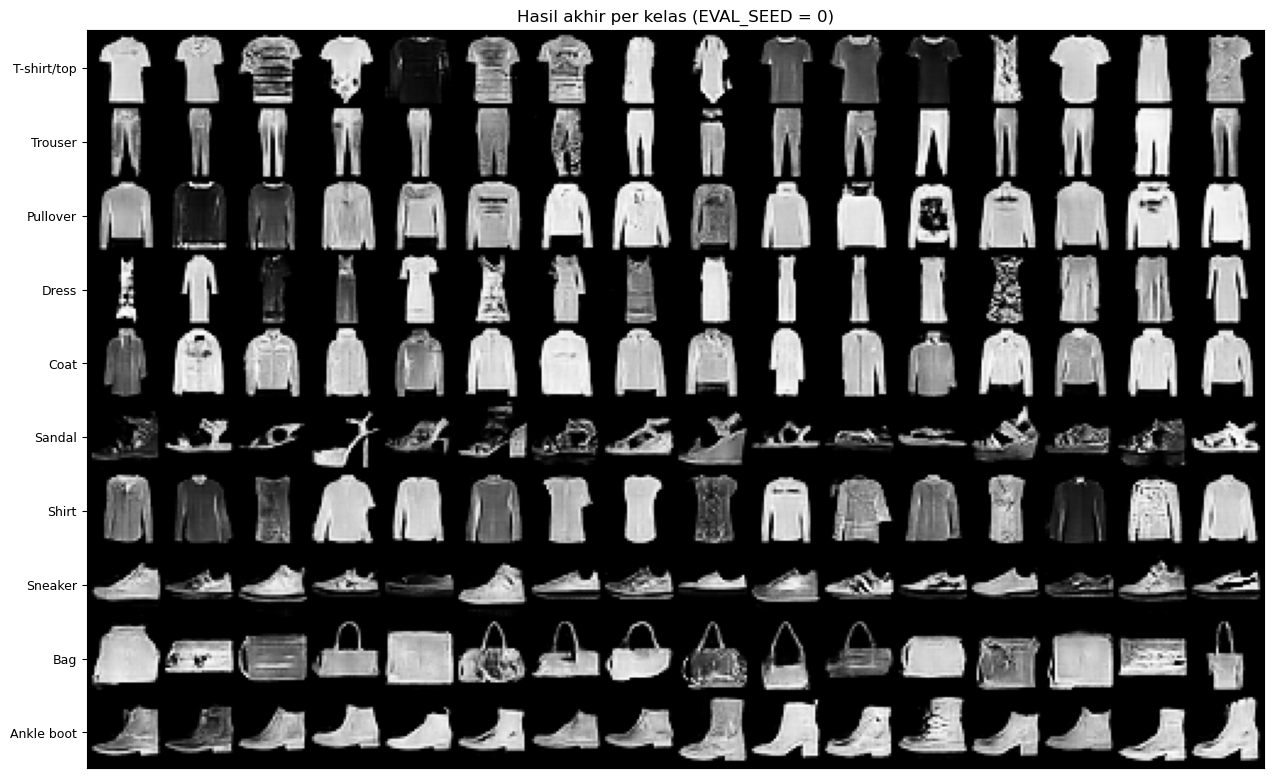

In [24]:
EVAL_SEED = 0          # ganti angka ini untuk melihat sampel lain
EVAL_PER_CLASS = 16    # gambar per kelas

eval_gen = torch.Generator().manual_seed(EVAL_SEED)
eval_z = torch.randn(
    cfg.num_classes * EVAL_PER_CLASS, cfg.latent_dim, generator=eval_gen
).to(device)                                                                                  # (N, latent_dim)
eval_labels = torch.arange(cfg.num_classes).repeat_interleave(EVAL_PER_CLASS).to(device)      # (N,)

generator.eval()
with torch.no_grad():
    eval_images = (generator(eval_z, eval_labels).cpu() + 1) / 2   # (N, C, H, W), balik ke [0, 1]
generator.train()

grid = make_grid(eval_images, nrow=EVAL_PER_CLASS, padding=2)      # (3, H', W'), satu baris per kelas

fig, ax = plt.subplots(figsize=(EVAL_PER_CLASS * 0.8, cfg.num_classes * 0.8))
ax.imshow(grid.permute(1, 2, 0))                                   # (H', W', 3)
ax.set_xticks([])
row_h = grid.shape[1] / cfg.num_classes
ax.set_yticks([(r + 0.5) * row_h for r in range(cfg.num_classes)])
ax.set_yticklabels(class_names, fontsize=9)
ax.set_title(f"Hasil akhir per kelas (EVAL_SEED = {EVAL_SEED})")

fig.tight_layout()
fig.savefig(fig_dir / "03_hasil_akhir_per_kelas.png", dpi=150)
plt.show()

## Sel 23b: Hasil Akhir per Kelas, Generator EMA

Sama dengan Sel 23 (`z` dan label identik), tapi memakai `ema_generator`. Bandingkan langsung dengan gambar Sel 23.

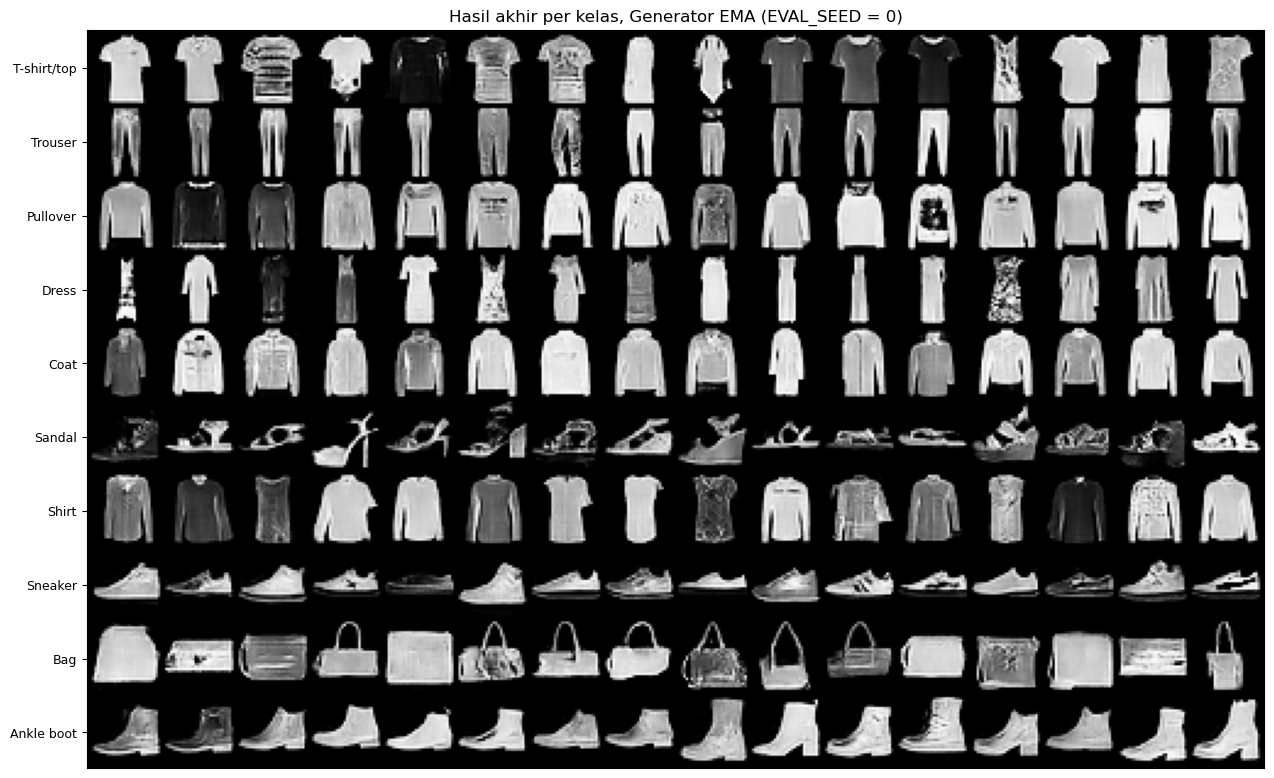

In [25]:
ema_generator.eval()
with torch.no_grad():
    ema_images = (ema_generator(eval_z, eval_labels).cpu() + 1) / 2   # (N, C, H, W), z dan label sama dengan Sel 23

grid = make_grid(ema_images, nrow=EVAL_PER_CLASS, padding=2)           # (3, H', W')

fig, ax = plt.subplots(figsize=(EVAL_PER_CLASS * 0.8, cfg.num_classes * 0.8))
ax.imshow(grid.permute(1, 2, 0))                                       # (H', W', 3)
ax.set_xticks([])
row_h = grid.shape[1] / cfg.num_classes
ax.set_yticks([(r + 0.5) * row_h for r in range(cfg.num_classes)])
ax.set_yticklabels(class_names, fontsize=9)
ax.set_title(f"Hasil akhir per kelas, Generator EMA (EVAL_SEED = {EVAL_SEED})")

fig.tight_layout()
fig.savefig(fig_dir / "03b_hasil_akhir_ema.png", dpi=150)
plt.show()

## Sel 24: Metrik Keragaman

Bandingkan rata-rata jarak L2 antar gambar buatan dengan antar gambar asli per kelas. Rasio yang jauh di bawah 1 menandakan keragaman Generator lebih rendah dari data asli. Ini indikator kasar, bacalah bersama grid gambar.

In [26]:
DIV_SAMPLES = 64  # jumlah gambar per kelas untuk menghitung keragaman


def mean_pairwise_l2(x):
    # x: (N, C, H, W) di [0, 1] -> rata-rata jarak L2 antar pasangan gambar berbeda
    flat = x.flatten(start_dim=1)                # (N, C*H*W)
    dist = torch.cdist(flat, flat)               # (N, N), diagonal = 0
    n = flat.size(0)
    return (dist.sum() / (n * (n - 1))).item()


div_gen = torch.Generator().manual_seed(EVAL_SEED)

print(f"{'Kelas':<14}{'asli':>8}{'buatan':>9}{'rasio':>8}")
generator.eval()
with torch.no_grad():
    for c in range(cfg.num_classes):
        # Gambar buatan: DIV_SAMPLES noise berbeda, label tetap c
        z = torch.randn(DIV_SAMPLES, cfg.latent_dim, generator=div_gen).to(device)  # (S, latent_dim)
        labels = torch.full((DIV_SAMPLES,), c, dtype=torch.long, device=device)     # (S,)
        fake = (generator(z, labels).cpu() + 1) / 2                                 # (S, C, H, W)

        # Gambar asli: DIV_SAMPLES sampel acak dari kelas c
        idx = (train_set.targets == c).nonzero(as_tuple=True)[0]                    # (N_c,)
        pick = idx[torch.randperm(len(idx), generator=div_gen)[:DIV_SAMPLES]]       # (S,)
        real = (torch.stack([train_set[i][0] for i in pick.tolist()]) + 1) / 2      # (S, C, H, W)

        real_div, fake_div = mean_pairwise_l2(real), mean_pairwise_l2(fake)
        print(f"{class_names[c]:<14}{real_div:>8.3f}{fake_div:>9.3f}{fake_div / real_div:>8.2f}")
generator.train()

Kelas             asli   buatan   rasio
T-shirt/top      8.904    8.902    1.00
Trouser          6.461    6.480    1.00
Pullover         8.847    9.468    1.07
Dress            8.553    7.630    0.89
Coat             9.127    8.743    0.96
Sandal           8.556    8.639    1.01
Shirt            9.015    9.081    1.01
Sneaker          6.700    6.149    0.92
Bag             11.346   10.874    0.96
Ankle boot       8.777    8.906    1.01


Generator(
  (label_embed): Embedding(10, 32)
  (project): Linear(in_features=132, out_features=12544, bias=True)
  (net): Sequential(
    (0): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (1): ReLU(inplace=True)
    (2): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (4): ReLU(inplace=True)
    (5): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (6): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): ReLU(inplace=True)
    (8): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): Conv2d(64, 1, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (12): Tanh()
  )
)

## Sel 25: Diagnosis BatchNorm, Statistik

Buat gambar dari `z` yang sama dengan salinan Generator di mode `eval()` dan `train()`. Hook mengukur selisih statistik running BatchNorm terhadap statistik batch (`mean_gap` dan `var_ratio`). Makin jauh dari 0 dan 1, makin besar kemungkinan bercak hitam berasal dari mode `eval()`.

In [27]:
import copy

# Salinan Generator, supaya statistik BatchNorm generator asli tidak ikut berubah
gen_eval = copy.deepcopy(generator).eval()    # statistik rata-rata (running), seperti di Sel 22 dan 23
gen_train = copy.deepcopy(generator).train()  # statistik batch saat ini

bn_gaps = []  # satu elemen per layer BatchNorm: (jumlah channel, mean_gap, var_ratio)


def record_bn_gap(module, inputs):
    # Dipanggil tepat sebelum BatchNorm bekerja, jadi running stats belum ikut diperbarui
    x = inputs[0].detach()                                 # (B, C, H, W)
    batch_mean = x.mean(dim=(0, 2, 3))                     # (C,)
    batch_var = x.var(dim=(0, 2, 3), unbiased=False)       # (C,)
    # mean_gap: selisih mean dalam satuan std batch; var_ratio: varians running / varians batch
    mean_gap = ((module.running_mean - batch_mean).abs() / batch_var.sqrt().clamp_min(1e-5)).mean().item()
    var_ratio = (module.running_var / batch_var.clamp_min(1e-5)).mean().item()
    bn_gaps.append((module.num_features, mean_gap, var_ratio))


hooks = [m.register_forward_pre_hook(record_bn_gap)
         for m in gen_train.modules() if isinstance(m, nn.BatchNorm2d)]

with torch.no_grad():
    imgs_eval = (gen_eval(eval_z, eval_labels).cpu() + 1) / 2     # (N, C, H, W), [0, 1]
    imgs_train = (gen_train(eval_z, eval_labels).cpu() + 1) / 2   # (N, C, H, W), [0, 1]

for h in hooks:
    h.remove()

for num_features, mean_gap, var_ratio in bn_gaps:
    print(f"BatchNorm ({num_features:>3} channel): mean_gap = {mean_gap:.3f}, var_ratio = {var_ratio:.3f}")
print(f"Rata-rata |eval - train| per piksel: {(imgs_eval - imgs_train).abs().mean().item():.4f}")

BatchNorm (256 channel): mean_gap = 0.014, var_ratio = 0.974
BatchNorm (128 channel): mean_gap = 0.006, var_ratio = 0.974
BatchNorm ( 64 channel): mean_gap = 0.007, var_ratio = 0.976
BatchNorm ( 64 channel): mean_gap = 0.017, var_ratio = 1.011
Rata-rata |eval - train| per piksel: 0.0104


## Sel 26: Diagnosis BatchNorm, Gambar

Bandingkan hasil kedua mode secara visual (8 gambar per kelas). Gambar disimpan ke `fig_dir`.

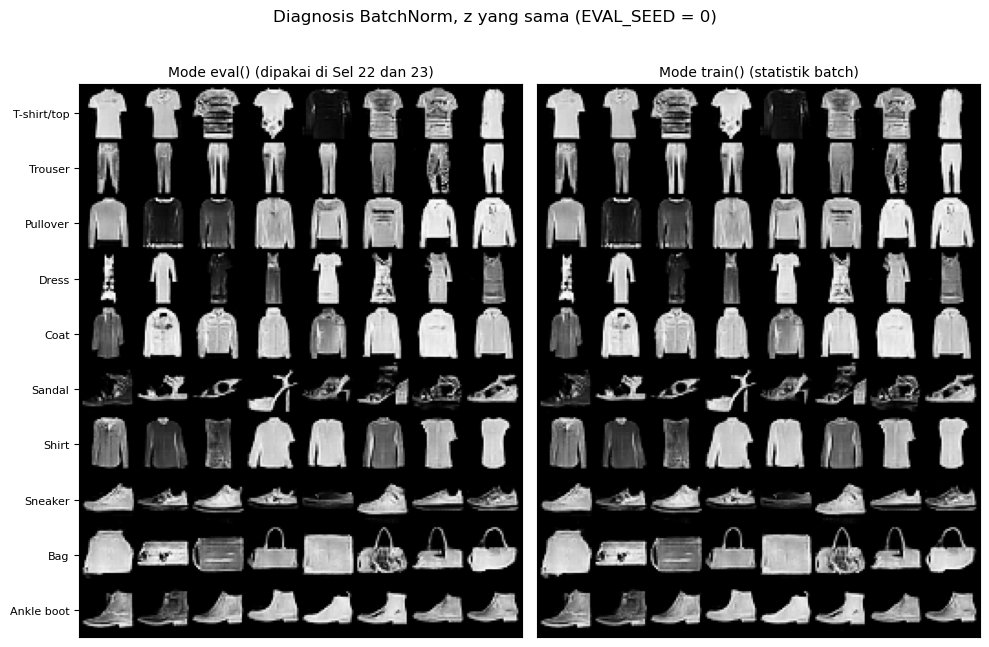

In [28]:
diag_per_class = 8  # gambar per kelas yang ditampilkan di tiap panel


def first_k_per_class(imgs, k):
    # imgs: (num_classes * EVAL_PER_CLASS, C, H, W), berurutan per kelas -> (num_classes * k, C, H, W)
    return imgs.view(cfg.num_classes, EVAL_PER_CLASS, *imgs.shape[1:])[:, :k].reshape(-1, *imgs.shape[1:])


panels = [("Mode eval() (dipakai di Sel 22 dan 23)", imgs_eval),
          ("Mode train() (statistik batch)", imgs_train)]

fig, axes = plt.subplots(1, 2, figsize=(10, 7))
for k, (ax, (title, imgs)) in enumerate(zip(axes, panels)):
    grid = make_grid(first_k_per_class(imgs, diag_per_class), nrow=diag_per_class, padding=2)  # (3, H', W')
    ax.imshow(grid.permute(1, 2, 0))                                                           # (H', W', 3)
    ax.set_title(title, fontsize=10)
    ax.set_xticks([])
    if k == 0:
        row_h = grid.shape[1] / cfg.num_classes
        ax.set_yticks([(r + 0.5) * row_h for r in range(cfg.num_classes)])
        ax.set_yticklabels(class_names, fontsize=8)
    else:
        ax.set_yticks([])

fig.suptitle(f"Diagnosis BatchNorm, z yang sama (EVAL_SEED = {EVAL_SEED})")
fig.tight_layout()
fig.savefig(fig_dir / "04_diagnosis_bn_eval_vs_train.png", dpi=150)
plt.show()

## Sel 27: Classifier Evaluasi

CNN kecil untuk menilai gambar buatan. `features()` memberi vektor fitur yang juga dipakai untuk jarak Frechet.

**Modul 8 tidak perlu melatih GAN ulang.** Pada kernel baru, cukup jalankan Sel 1, 2, 3, 7, dan 8 (import, config, data, `GanConfig`, `Generator`), lalu sel-sel Modul 8.

In [29]:
class Classifier(nn.Module):
    def __init__(self, cfg, base_channels=32, feature_dim=128):
        super().__init__()
        # Dua tahap pooling /2, jadi sisi gambar harus habis dibagi 4
        assert cfg.image_size % 4 == 0, "cfg.image_size harus habis dibagi 4"
        final_size = cfg.image_size // 4  # 28 -> 7

        self.body = nn.Sequential(
            # (B, C, H, W) -> (B, base, H/2, W/2)
            nn.Conv2d(cfg.channels, base_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            # (B, base, H/2, W/2) -> (B, 2*base, H/4, W/4)
            nn.Conv2d(base_channels, base_channels * 2, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Flatten(),  # (B, 2*base*final_size*final_size)
            nn.Linear(base_channels * 2 * final_size ** 2, feature_dim),
            nn.ReLU(inplace=True),  # (B, feature_dim)
        )
        self.dropout = nn.Dropout(0.3)
        self.head = nn.Linear(feature_dim, cfg.num_classes)

    def features(self, x):
        # x: (B, C, H, W) -> fitur (B, feature_dim), dipakai juga untuk jarak Frechet
        return self.body(x)

    def forward(self, x):
        return self.head(self.dropout(self.features(x)))  # (B, num_classes)


check_clf = Classifier(cfg).to(device)
dummy = torch.zeros(cfg.batch_size, cfg.channels, cfg.image_size, cfg.image_size, device=device)  # (B, C, H, W)
print(f"logits shape : {tuple(check_clf(dummy).shape)}")             # harapan: (128, 10)
print(f"fitur shape  : {tuple(check_clf.features(dummy).shape)}")    # harapan: (128, 128)
print(f"jumlah parameter: {sum(p.numel() for p in check_clf.parameters()):,}")

logits shape : (128, 10)
fitur shape  : (128, 128)
jumlah parameter: 421,642


## Sel 28: Latih atau Muat Classifier

Latih classifier pada data asli (atau muat dari `checkpoints/classifier.pt` kalau sudah ada), lalu ukur akurasinya pada 10.000 gambar uji asli sebagai batas atas.

In [30]:
import torch.nn.functional as F
from pathlib import Path

CLF_EPOCHS = 5                                   # epoch training classifier
CLF_LR = 1e-3                                    # learning rate Adam
CLF_PATH = Path("./checkpoints/classifier.pt")   # bobot disimpan supaya classifier sama di semua sesi

# Data uji asli (10.000 gambar), tidak pernah dipakai melatih GAN maupun classifier
test_set = datasets.FashionMNIST(root=cfg.data_root, train=False, download=True, transform=transform)
test_loader = DataLoader(test_set, batch_size=cfg.batch_size, shuffle=False, num_workers=cfg.num_workers)

set_seed(SEED)
classifier = Classifier(cfg).to(device)

if CLF_PATH.exists():
    classifier.load_state_dict(torch.load(CLF_PATH, map_location=device))
    print(f"Classifier dimuat dari {CLF_PATH.resolve()}")
else:
    optimizer = torch.optim.Adam(classifier.parameters(), lr=CLF_LR)
    classifier.train()
    for epoch in range(1, CLF_EPOCHS + 1):
        loss_sum = torch.zeros((), device=device)
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)  # (B, C, H, W), (B,)
            loss = F.cross_entropy(classifier(images), labels)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            loss_sum += loss.detach()
        print(f"Epoch {epoch}/{CLF_EPOCHS} | loss {loss_sum.item() / len(train_loader):.4f}")
    CLF_PATH.parent.mkdir(parents=True, exist_ok=True)
    torch.save(classifier.state_dict(), CLF_PATH)
    print(f"Classifier disimpan di {CLF_PATH.resolve()}")

# Akurasi pada gambar uji asli: batas atas untuk akurasi gambar buatan
classifier.eval()
correct = torch.zeros(cfg.num_classes, dtype=torch.long)
total = torch.zeros(cfg.num_classes, dtype=torch.long)
with torch.no_grad():
    for images, labels in test_loader:
        pred = classifier(images.to(device)).argmax(dim=1).cpu()  # (B,)
        correct += torch.bincount(labels[pred == labels], minlength=cfg.num_classes)
        total += torch.bincount(labels, minlength=cfg.num_classes)

real_acc = correct.float() / total  # (num_classes,)
print(f"Akurasi gambar asli (uji): {correct.sum().item() / total.sum().item() * 100:.2f}%")
for name, acc in zip(class_names, real_acc.tolist()):
    print(f"  {name:<14}{acc * 100:6.2f}%")

Classifier dimuat dari /Users/maulidahelyati/Library/CloudStorage/GoogleDrive-maulida.helya@gmail.com/My Drive/Tugas Gen AI/Tugas_Vibe_Coding/notebooks/checkpoints/classifier.pt
Akurasi gambar asli (uji): 91.03%
  T-shirt/top    88.00%
  Trouser        98.50%
  Pullover       89.70%
  Dress          90.90%
  Coat           85.30%
  Sandal         98.40%
  Shirt          68.20%
  Sneaker        97.80%
  Bag            98.10%
  Ankle boot     95.40%


## Sel 29: Fungsi Evaluasi

Muat Generator dari checkpoint, buat gambar per kelas dari `z` tetap, klasifikasi, dan hitung akurasi, matriks konfusi, serta jarak Frechet pada fitur classifier. Ini bukan FID standar: fiturnya dari classifier kita, jadi angkanya hanya untuk membandingkan run di sini. `sample_z` membuat noise biasa atau noise terpotong (`trunc`), dan `evaluate_generator` menerima `trunc`.

In [31]:
GEN_PER_CLASS = 1000   # gambar buatan per kelas (10 kelas x 1000 = 10.000, sama dengan jumlah data uji)
GEN_SEED = 0           # seed noise z, sama untuk semua checkpoint
GEN_BATCH = 500        # ukuran batch saat membuat dan mengklasifikasi gambar


def sample_z(n, trunc=None, seed=GEN_SEED):
    # Noise N(0, 1). Dengan trunc, nilai di luar [-trunc, trunc] diambil ulang sampai semuanya masuk
    gen = torch.Generator().manual_seed(seed)
    z = torch.randn(n, cfg.latent_dim, generator=gen)  # (n, latent_dim)
    if trunc is not None:
        outside = z.abs() > trunc
        while outside.any():
            z[outside] = torch.randn(int(outside.sum()), generator=gen)
            outside = z.abs() > trunc
    return z


def load_generator(path, base_channels, epoch, key="generator", refine=False):
    ckpt = torch.load(path, map_location=device)
    assert ckpt["epoch"] == epoch, f"{path}: berisi epoch {ckpt['epoch']}, diharapkan {epoch}"
    gen = Generator(cfg, base_channels=base_channels, refine=refine).to(device)
    gen.load_state_dict(ckpt[key])
    return gen.eval()


def evaluate_generator(gen, trunc=None):
    k = cfg.num_classes
    z = sample_z(k * GEN_PER_CLASS, trunc)                                                                 # (N, latent_dim)
    labels = torch.arange(k).repeat_interleave(GEN_PER_CLASS)                                              # (N,)

    preds, feats = [], []
    with torch.no_grad():
        for start in range(0, len(z), GEN_BATCH):
            z_b = z[start:start + GEN_BATCH].to(device)           # (b, latent_dim)
            y_b = labels[start:start + GEN_BATCH].to(device)      # (b,)
            f_b = classifier.features(gen(z_b, y_b))              # (b, feature_dim)
            preds.append(classifier.head(f_b).argmax(dim=1).cpu())  # (b,)
            feats.append(f_b.cpu())
    preds, feats = torch.cat(preds), torch.cat(feats)             # (N,), (N, feature_dim)

    conf = torch.bincount(labels * k + preds, minlength=k * k).view(k, k)  # baris = kelas diminta, kolom = prediksi
    acc = conf.diag().float() / conf.sum(dim=1)                            # (k,)
    return acc, conf, feats


def frechet_distance(feat_a, feat_b):
    # feat_*: (N, D). Jarak Frechet antara dua Gaussian: |mu_a - mu_b|^2 + Tr(A) + Tr(B) - 2 Tr sqrt(A B)
    a, b = feat_a.double(), feat_b.double()
    mu_a, mu_b = a.mean(dim=0), b.mean(dim=0)  # (D,)
    cov_a, cov_b = torch.cov(a.T), torch.cov(b.T)  # (D, D)
    # Tr sqrt(A B) = Tr sqrt(A^(1/2) B A^(1/2)), matriks simetrik sehingga stabil dengan eigh
    eigval, eigvec = torch.linalg.eigh(cov_a)
    sqrt_a = (eigvec * eigval.clamp_min(0).sqrt()) @ eigvec.T       # (D, D)
    inner = sqrt_a @ cov_b @ sqrt_a                                  # (D, D)
    tr_sqrt = torch.linalg.eigvalsh(inner).clamp_min(0).sqrt().sum()
    return ((mu_a - mu_b) ** 2).sum().item() + cov_a.trace().item() + cov_b.trace().item() - 2 * tr_sqrt.item()

## Sel 30: Fitur Gambar Asli dan Batas Bawah Frechet

Ekstrak fitur 10.000 gambar uji asli sebagai pembanding, dan ukur jarak Frechet antara dua sampel gambar asli (latih vs uji) untuk gambaran skala jarak terbaik yang mungkin.

In [32]:
def extract_features(loader, max_items):
    # Fitur classifier dari gambar asli: (max_items, feature_dim)
    feats, n = [], 0
    with torch.no_grad():
        for images, _ in loader:
            feats.append(classifier.features(images.to(device)).cpu())
            n += images.size(0)
            if n >= max_items:
                break
    return torch.cat(feats)[:max_items]


real_test_feats = extract_features(test_loader, len(test_set))     # (10000, feature_dim)
real_train_feats = extract_features(train_loader, len(test_set))   # (10000, feature_dim), jumlah sama dengan uji

# Batas bawah: jarak antara dua sampel gambar asli yang berbeda
fd_floor = frechet_distance(real_train_feats, real_test_feats)
print(f"Jarak Frechet asli (latih) vs asli (uji): {fd_floor:.3f}")

Jarak Frechet asli (latih) vs asli (uji): 0.429


## Sel 31: Evaluasi Semua Checkpoint

Jalankan evaluasi untuk semua run dan checkpoint (run di `EMA_RUNS` memakai bobot EMA), cetak tabel (akurasi per kelas dan jarak Frechet), dan simpan ke `figures/eval_classifier/eval_classifier.csv`.

In [33]:
import csv

# Nama run -> daftar (epoch, file checkpoint, base_channels Generator)
RUNS = {
    "baseline G128/D64": [(20, "checkpoints/cgan_last.pt", 128)],
    "G128/D64": [(50, "checkpoints/run_epochs50/cgan_last.pt", 128)],
    "G256/D128": [(e, f"checkpoints/run_cap256_e50/cgan_epoch_{e:03d}.pt", 256) for e in (10, 20, 30, 40, 50)],
    "G256/D64": [(e, f"checkpoints/run_g256_d64_e50/cgan_epoch_{e:03d}.pt", 256) for e in (10, 20, 30, 40, 50)],
    "G256/D64 +DCGAN s42": [(e, f"checkpoints/run_g256_d64_dcgan_s42_e50/cgan_epoch_{e:03d}.pt", 256) for e in (10, 20, 30, 40, 50)],
    "G256/D64 s43": [(e, f"checkpoints/run_g256_d64_noinit_s43_e50/cgan_epoch_{e:03d}.pt", 256) for e in (10, 20, 30, 40, 50)],
    "G256/D64 +DCGAN s43": [(e, f"checkpoints/run_g256_d64_dcgan_s43_e50/cgan_epoch_{e:03d}.pt", 256) for e in (10, 20, 30, 40, 50)],
    "G256/D64 s43 e100": [(e, f"checkpoints/run_g256_d64_noinit_s43_e100/cgan_epoch_{e:03d}.pt", 256) for e in range(10, 101, 10)],
    "G256/D64 EMA live": [(e, f"checkpoints/run_g256_d64_noinit_s43_e100_ema/cgan_epoch_{e:03d}.pt", 256) for e in range(10, 101, 10)],
    "G256/D64 EMA": [(e, f"checkpoints/run_g256_d64_noinit_s43_e100_ema/cgan_epoch_{e:03d}.pt", 256) for e in range(10, 101, 10)],
    "G256/D64 EMA e200 live": [(e, f"checkpoints/run_g256_d64_noinit_s43_e200_ema/cgan_epoch_{e:03d}.pt", 256) for e in range(10, 201, 10)],
    "G256/D64 EMA e200": [(e, f"checkpoints/run_g256_d64_noinit_s43_e200_ema/cgan_epoch_{e:03d}.pt", 256) for e in range(10, 201, 10)],
    "G256+conv live": [(e, f"checkpoints/run_g256_conv_d64_noinit_s43_e100_ema/cgan_epoch_{e:03d}.pt", 256) for e in range(10, 101, 10)],
    "G256+conv EMA": [(e, f"checkpoints/run_g256_conv_d64_noinit_s43_e100_ema/cgan_epoch_{e:03d}.pt", 256) for e in range(10, 101, 10)],
    "G256+conv D128 live": [(e, f"checkpoints/run_g256_conv_d128_noinit_s43_e100_ema/cgan_epoch_{e:03d}.pt", 256) for e in range(10, 101, 10)],
    "G256+conv D128 EMA": [(e, f"checkpoints/run_g256_conv_d128_noinit_s43_e100_ema/cgan_epoch_{e:03d}.pt", 256) for e in range(10, 101, 10)],
    "G256+conv D256 e50 live": [(e, f"checkpoints/run_g256_conv_d256_noinit_s43_e50_ema/cgan_epoch_{e:03d}.pt", 256) for e in range(10, 51, 10)],
    "G256+conv D256 e50 EMA": [(e, f"checkpoints/run_g256_conv_d256_noinit_s43_e50_ema/cgan_epoch_{e:03d}.pt", 256) for e in range(10, 51, 10)],
    "G256+conv D256 live": [(e, f"checkpoints/run_g256_conv_d256_noinit_s43_e100_ema/cgan_epoch_{e:03d}.pt", 256) for e in range(10, 101, 10)],
    "G256+conv D256 EMA": [(e, f"checkpoints/run_g256_conv_d256_noinit_s43_e100_ema/cgan_epoch_{e:03d}.pt", 256) for e in range(10, 101, 10)],
    "TTUR lr_d 4e-4 live": [(e, f"checkpoints/run_g256_conv_d128_noinit_lrd0.0004_s43_e100_ema/cgan_epoch_{e:03d}.pt", 256) for e in range(10, 101, 10)],
    "TTUR lr_d 4e-4 EMA": [(e, f"checkpoints/run_g256_conv_d128_noinit_lrd0.0004_s43_e100_ema/cgan_epoch_{e:03d}.pt", 256) for e in range(10, 101, 10)],
    "TTUR s44 live": [(e, f"checkpoints/run_g256_conv_d128_noinit_lrd0.0004_s44_e100_ema/cgan_epoch_{e:03d}.pt", 256) for e in range(10, 101, 10)],
    "TTUR s44 EMA": [(e, f"checkpoints/run_g256_conv_d128_noinit_lrd0.0004_s44_e100_ema/cgan_epoch_{e:03d}.pt", 256) for e in range(10, 101, 10)],
}
EMA_RUNS = {"G256/D64 EMA", "G256/D64 EMA e200", "G256+conv EMA", "G256+conv D128 EMA", "G256+conv D256 e50 EMA",
           "G256+conv D256 EMA",
           "TTUR lr_d 4e-4 EMA", "TTUR s44 EMA"}  # run yang memakai bobot ema_generator dari checkpoint, bukan generator
REFINE_RUNS = {"G256+conv live", "G256+conv EMA", "G256+conv D128 live", "G256+conv D128 EMA",
               "G256+conv D256 e50 live", "G256+conv D256 e50 EMA",
               "G256+conv D256 live", "G256+conv D256 EMA",
               "TTUR lr_d 4e-4 live", "TTUR lr_d 4e-4 EMA",
               "TTUR s44 live", "TTUR s44 EMA"}  # run dengan Generator refine=True

EVAL_DIR = Path("./figures/eval_classifier")
EVAL_DIR.mkdir(parents=True, exist_ok=True)

results = []  # satu dict per checkpoint
for run, entries in RUNS.items():
    for epoch, ckpt_path, base_channels in entries:
        if not Path(ckpt_path).exists():
            print(f"Dilewati (belum ada): {ckpt_path}")
            continue
        acc, conf, feats = evaluate_generator(load_generator(ckpt_path, base_channels, epoch,
                                                       "ema_generator" if run in EMA_RUNS else "generator",
                                                       run in REFINE_RUNS))
        results.append({"run": run, "epoch": epoch, "acc": acc, "conf": conf,
                        "fd": frechet_distance(feats, real_test_feats)})

short = [name[:6] for name in class_names]
print(f"{'Run':<19}{'Epoch':>6}{'Akurasi':>9}{'Frechet':>9} | " + " ".join(f"{s:>6}" for s in short))
for r in results:
    print(f"{r['run']:<19}{r['epoch']:>6}{r['acc'].mean().item() * 100:>8.1f}%{r['fd']:>9.2f} | "
          + " ".join(f"{a * 100:>6.1f}" for a in r["acc"].tolist()))
print(f"{'Gambar asli (uji)':<19}{'-':>6}{real_acc.mean().item() * 100:>8.1f}%{fd_floor:>9.2f} | "
      + " ".join(f"{a * 100:>6.1f}" for a in real_acc.tolist()))

with open(EVAL_DIR / "eval_classifier.csv", "w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(["run", "epoch", "mean_acc", "frechet"] + [f"acc_{name}" for name in class_names])
    for r in results:
        writer.writerow([r["run"], r["epoch"], f"{r['acc'].mean().item():.4f}", f"{r['fd']:.4f}"]
                        + [f"{a:.4f}" for a in r["acc"].tolist()])

Run                 Epoch  Akurasi  Frechet | T-shir Trouse Pullov  Dress   Coat Sandal  Shirt Sneake    Bag Ankle 
baseline G128/D64      20    91.6%     6.38 |   90.7   99.5   91.6   90.5   81.5   98.4   70.4   97.2   98.8   97.4
G128/D64               50    91.4%     3.42 |   89.8   99.8   92.6   91.3   82.2   98.6   64.4   98.4   99.4   97.2
G256/D128              10    91.5%    13.35 |   90.8   99.8   87.4   91.0   84.8   97.5   71.8   97.2   97.8   96.4
G256/D128              20    91.1%     5.66 |   88.8   99.7   92.3   92.7   85.7   97.3   63.6   96.7   98.1   95.9
G256/D128              30    92.3%     4.09 |   89.7   99.6   93.1   92.6   85.7   98.5   73.1   98.1   98.4   94.5
G256/D128              40    91.7%     3.49 |   92.2   99.8   93.9   92.0   83.2   97.4   65.4   97.5   98.2   97.1
G256/D128              50    91.5%     3.21 |   92.1   99.9   92.1   94.4   79.7   96.8   66.0   98.5   98.1   97.1
G256/D64               10    90.0%    21.80 |   87.4   99.9   87.2   86.

## Sel 32: Grafik dan Matriks Konfusi

Grafik akurasi dan jarak Frechet per epoch, serta matriks konfusi untuk satu checkpoint (ganti `CONF_RUN` dan `CONF_EPOCH`). Disimpan ke `figures/eval_classifier/`.

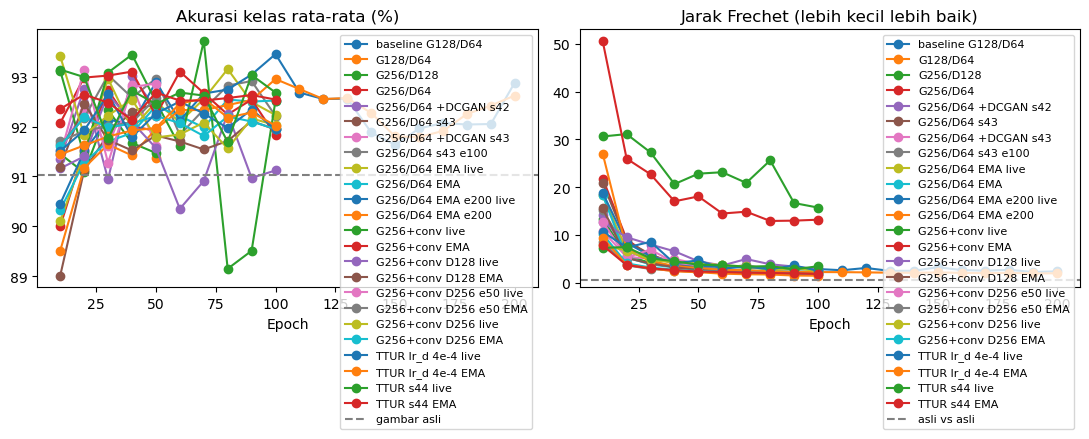

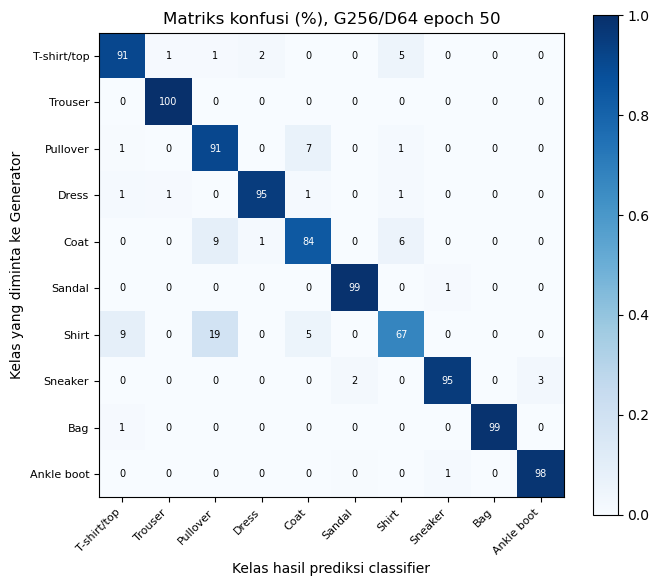

In [34]:
CONF_RUN = "G256/D64"   # run untuk matriks konfusi
CONF_EPOCH = 50         # epoch untuk matriks konfusi

# Akurasi dan jarak Frechet per epoch
fig, (ax_acc, ax_fd) = plt.subplots(1, 2, figsize=(11, 4))
for run in RUNS:
    rs = [r for r in results if r["run"] == run]
    if not rs:
        continue
    epochs = [r["epoch"] for r in rs]
    ax_acc.plot(epochs, [r["acc"].mean().item() * 100 for r in rs], marker="o", label=run)
    ax_fd.plot(epochs, [r["fd"] for r in rs], marker="o", label=run)
ax_acc.axhline(real_acc.mean().item() * 100, linestyle="--", color="gray", label="gambar asli")
ax_fd.axhline(fd_floor, linestyle="--", color="gray", label="asli vs asli")
ax_acc.set_title("Akurasi kelas rata-rata (%)")
ax_fd.set_title("Jarak Frechet (lebih kecil lebih baik)")
for ax in (ax_acc, ax_fd):
    ax.set_xlabel("Epoch")
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(EVAL_DIR / "01_akurasi_frechet_per_epoch.png", dpi=150)
plt.show()

# Matriks konfusi: baris = kelas yang diminta, kolom = kelas hasil prediksi
matches = [r for r in results if r["run"] == CONF_RUN and r["epoch"] == CONF_EPOCH]
assert matches, f"Tidak ada hasil untuk {CONF_RUN} epoch {CONF_EPOCH}"
conf = matches[0]["conf"]
conf_norm = conf.float() / conf.sum(dim=1, keepdim=True)  # (K, K), tiap baris berjumlah 1

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(conf_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(cfg.num_classes))
ax.set_xticklabels(class_names, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(cfg.num_classes))
ax.set_yticklabels(class_names, fontsize=8)
for i in range(cfg.num_classes):
    for j in range(cfg.num_classes):
        ax.text(j, i, f"{conf_norm[i, j].item() * 100:.0f}", ha="center", va="center", fontsize=7,
                color="white" if conf_norm[i, j] > 0.5 else "black")
ax.set_xlabel("Kelas hasil prediksi classifier")
ax.set_ylabel("Kelas yang diminta ke Generator")
ax.set_title(f"Matriks konfusi (%), {CONF_RUN} epoch {CONF_EPOCH}")
fig.colorbar(im, ax=ax)
fig.tight_layout()
fig.savefig(EVAL_DIR / f"02_konfusi_{CONF_RUN.replace('/', '_').replace(' ', '_')}_e{CONF_EPOCH}.png", dpi=150)
plt.show()

## Sel 33: Truncation Trick, Metrik

Buat gambar dari noise yang dipotong (`|z| <= trunc`, nilai di luar batas diambil ulang) memakai bobot EMA. Batas lebih kecil biasanya mengurangi gambar aneh, tapi juga keragaman. Tabel melaporkan akurasi, jarak Frechet, dan keragaman relatif terhadap tanpa truncation, pada `GEN_SEED` dan jumlah sampel yang sama dengan Sel 31.

In [35]:
TRUNC_CKPT = "checkpoints/run_g256_conv_d128_noinit_s43_e100_ema/cgan_epoch_100.pt"
TRUNC_EPOCH = 100
TRUNC_REFINE = True                         # True jika checkpoint dilatih dengan Generator refine=True
TRUNC_VALUES = [None, 2.0, 1.5, 1.0, 0.7]   # batas |z|; None = tanpa truncation
TRUNC_CLASSES = [0, 2, 3, 6]                # T-shirt/top, Pullover, Dress, Shirt
VIS_PER_CLASS = 12                          # gambar per kelas pada gambar perbandingan

gen_trunc = load_generator(TRUNC_CKPT, 256, TRUNC_EPOCH, "ema_generator", TRUNC_REFINE)


def mean_class_diversity(gen, trunc):
    # Rata-rata (atas kelas) jarak L2 antar pasangan gambar buatan, ruang piksel [0, 1]
    z_all = sample_z(cfg.num_classes * DIV_SAMPLES, trunc)  # (K * S, latent_dim)
    divs = []
    with torch.no_grad():
        for c in range(cfg.num_classes):
            z = z_all[c * DIV_SAMPLES:(c + 1) * DIV_SAMPLES].to(device)           # (S, latent_dim)
            labels = torch.full((DIV_SAMPLES,), c, dtype=torch.long, device=device)  # (S,)
            divs.append(mean_pairwise_l2((gen(z, labels).cpu() + 1) / 2))
    return sum(divs) / len(divs)


rows = []
for trunc in TRUNC_VALUES:
    acc, _, feats = evaluate_generator(gen_trunc, trunc)
    rows.append({"trunc": trunc, "acc": acc, "fd": frechet_distance(feats, real_test_feats),
                 "div": mean_class_diversity(gen_trunc, trunc)})

print(f"Checkpoint: {TRUNC_CKPT} (bobot EMA)")
print(f"{'trunc':>6}{'Akurasi':>9}{'Frechet':>9}{'Keragaman':>11} | " + " ".join(f"{n[:6]:>6}" for n in class_names))
for r in rows:
    label = "tanpa" if r["trunc"] is None else f"{r['trunc']:.1f}"
    print(f"{label:>6}{r['acc'].mean().item() * 100:>8.1f}%{r['fd']:>9.2f}{r['div'] / rows[0]['div']:>11.2f} | "
          + " ".join(f"{a * 100:>6.1f}" for a in r["acc"].tolist()))
print("Keragaman: relatif terhadap tanpa truncation (1.00).")

Checkpoint: checkpoints/run_g256_conv_d128_noinit_s43_e100_ema/cgan_epoch_100.pt (bobot EMA)
 trunc  Akurasi  Frechet  Keragaman | T-shir Trouse Pullov  Dress   Coat Sandal  Shirt Sneake    Bag Ankle 
 tanpa    91.9%     1.80       1.00 |   90.6   99.7   91.9   93.1   84.7   98.7   67.9   97.0   99.1   96.7
   2.0    93.8%     3.42       0.95 |   94.5   99.8   94.7   94.5   89.0   98.3   70.6   98.3   99.1   99.0
   1.5    96.0%     7.18       0.86 |   95.1  100.0   97.6   97.5   92.0   98.5   80.2   99.3   99.9   99.5
   1.0    98.0%    18.81       0.71 |   98.9  100.0   99.3   99.7   95.1   99.6   87.2  100.0  100.0  100.0
   0.7    99.0%    32.71       0.58 |  100.0  100.0  100.0   99.9   96.6   99.9   93.7  100.0  100.0  100.0
Keragaman: relatif terhadap tanpa truncation (1.00).


## Sel 34: Truncation Trick, Gambar

Bandingkan T-shirt/top, Pullover, Dress, dan Shirt untuk tiap nilai `trunc`. Gambar disimpan di `figures/eval_classifier`.

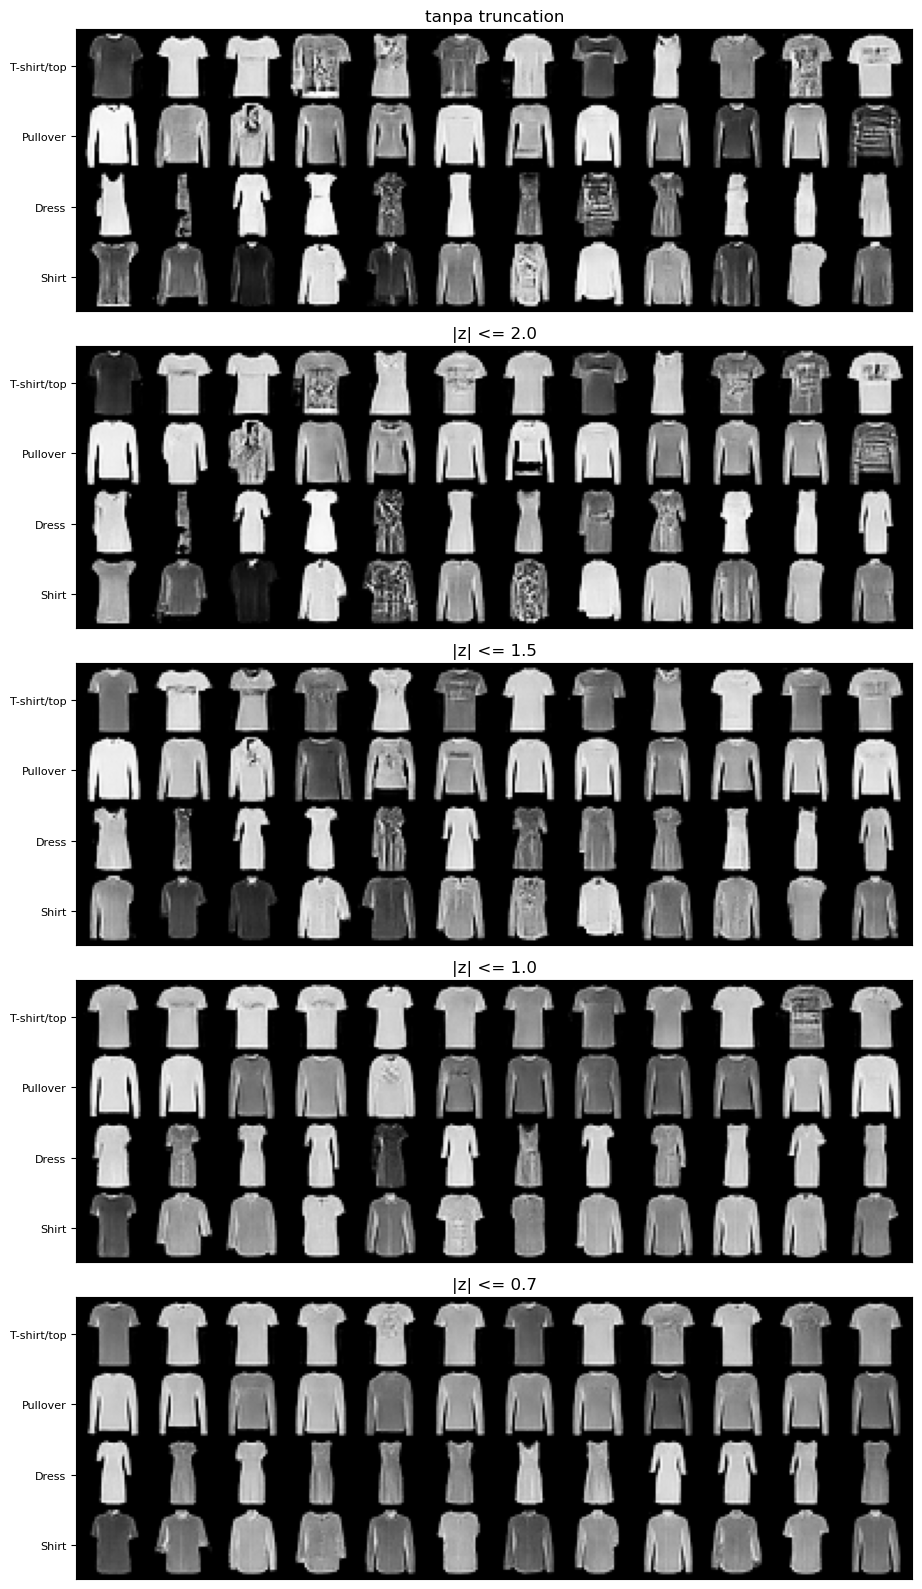

In [36]:
fig, axes = plt.subplots(len(TRUNC_VALUES), 1, figsize=(VIS_PER_CLASS * 0.75, len(TRUNC_VALUES) * len(TRUNC_CLASSES) * 0.75 + 1))
for ax, trunc in zip(axes, TRUNC_VALUES):
    # Noise berbeda per nilai trunc (diambil ulang), tapi seed dan label sama
    z = sample_z(len(TRUNC_CLASSES) * VIS_PER_CLASS, trunc, seed=EVAL_SEED).to(device)  # (N, latent_dim)
    labels = torch.tensor(TRUNC_CLASSES).repeat_interleave(VIS_PER_CLASS).to(device)    # (N,)
    with torch.no_grad():
        imgs = (gen_trunc(z, labels).cpu() + 1) / 2                                      # (N, C, H, W)
    grid = make_grid(imgs, nrow=VIS_PER_CLASS, padding=2)                                # (3, H', W')
    ax.imshow(grid.permute(1, 2, 0))                                                     # (H', W', 3)
    ax.set_title("tanpa truncation" if trunc is None else f"|z| <= {trunc}")
    ax.set_xticks([])
    row_h = grid.shape[1] / len(TRUNC_CLASSES)
    ax.set_yticks([(r + 0.5) * row_h for r in range(len(TRUNC_CLASSES))])
    ax.set_yticklabels([class_names[c] for c in TRUNC_CLASSES], fontsize=8)
fig.tight_layout()
fig.savefig(EVAL_DIR / f"03_truncation_{Path(TRUNC_CKPT).parent.name}.png", dpi=150)
plt.show()